In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_csv(r"C:\Users\medisa\Downloads\archive (8)\online_retail_II.csv")

In [3]:
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,12/1/2009 7:45,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,12/1/2009 7:45,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,12/1/2009 7:45,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,12/1/2009 7:46,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,12/1/2009 7:46,3.75,13085.0,United Kingdom


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1048575 non-null  object 
 1   StockCode    1048575 non-null  object 
 2   Description  1044203 non-null  object 
 3   Quantity     1048575 non-null  int64  
 4   InvoiceDate  1048575 non-null  object 
 5   Price        1048575 non-null  float64
 6   Customer ID  811893 non-null   float64
 7   Country      1048575 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 64.0+ MB


In [5]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4372
Quantity            0
InvoiceDate         0
Price               0
Customer ID    236682
Country             0
dtype: int64

In [6]:
df = df.dropna()

In [7]:
df.drop_duplicates()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1048570,580501,23284,DOORMAT KEEP CALM AND COME IN,2,12/4/2011 13:00,8.25,14546.0,United Kingdom
1048571,580501,22507,MEMO BOARD RETROSPOT DESIGN,3,12/4/2011 13:00,4.95,14546.0,United Kingdom
1048572,580502,22469,HEART OF WICKER SMALL,3,12/4/2011 13:15,1.65,16931.0,United Kingdom
1048573,580502,23489,VINTAGE BELLS GARLAND,2,12/4/2011 13:15,2.89,16931.0,United Kingdom


In [8]:
df.dtypes

Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object

In [9]:
df.shape

(811893, 8)

In [10]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])

In [11]:
df['Revenue']=df['Quantity']*df['Price']

In [12]:
cancelled = df[
    df['Invoice'].astype(str).str.startswith('C')
]

print("Cancelled rows:", len(cancelled))
print("Cancelled invoices:", cancelled['Invoice'].nunique())

Cancelled rows: 18513
Cancelled invoices: 7815


In [13]:
sales_df = df[
    (~df['Invoice'].astype(str).str.startswith('C')) &
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].copy()

sales_df['Revenue'] = sales_df['Quantity'] * sales_df['Price']

print("Rows before cleaning:", len(df))
print("Rows after filtering:", len(sales_df))
print("Gross sales revenue:", sales_df['Revenue'].sum())

Rows before cleaning: 811893
Rows after filtering: 793309
Gross sales revenue: 17324932.088000003


How many unique products are sold by the retailer?

In [14]:
df['StockCode'].nunique()

4645

How much revenue does the retailer generate each month?

In [15]:
#sales_2009 = sales_df[
    #sales_df['InvoiceDate'].dt.year == 2009
#]

monthly_revenue=sales_df.groupby(
    sales_df['InvoiceDate'].dt.to_period('M')
    
)['Revenue'].sum()
print(monthly_revenue)

InvoiceDate
2009-12     686654.160
2010-01     557319.062
2010-02     506371.066
2010-03     699608.991
2010-04     594609.192
2010-05     599985.790
2010-06     639066.580
2010-07     591636.740
2010-08     604242.650
2010-09     831615.001
2010-10    1036680.000
2010-11    1172336.042
2010-12     884591.890
2011-01     569445.040
2011-02     447137.350
2011-03     595500.760
2011-04     469200.361
2011-05     678594.560
2011-06     661213.690
2011-07     600091.011
2011-08     645343.900
2011-09     952838.382
2011-10    1039318.790
2011-11    1161817.380
2011-12      99713.700
Freq: M, Name: Revenue, dtype: float64


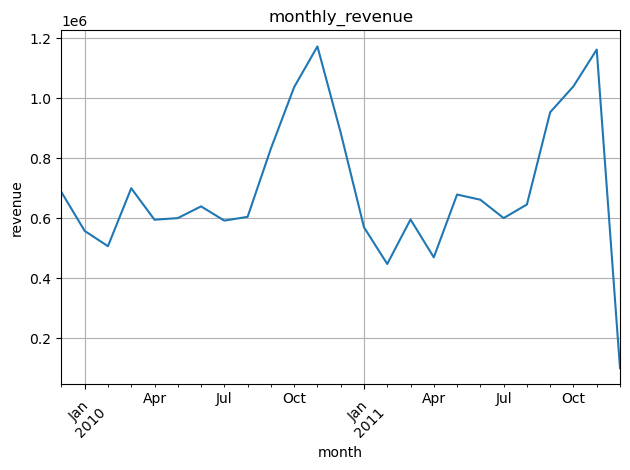

In [16]:
monthly_revenue.plot(
    kind='line'
    
)
plt.title('monthly_revenue')
plt.xlabel('month')
plt.ylabel('revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Which countries have the highest number of transactions?

In [17]:
country_transactions=(
    sales_df.groupby('Country')['Invoice']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)
print(country_transactions)

Country
United Kingdom    33085
Germany             775
France              601
EIRE                560
Netherlands         225
Spain               152
Belgium             146
Sweden              103
Australia            95
Switzerland          90
Name: Invoice, dtype: int64


Which products have the highest total quantity sold?

In [18]:
top_products=(
    sales_df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)  
)
print(top_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     108100
WHITE HANGING HEART T-LIGHT HOLDER     93056
ASSORTED COLOUR BIRD ORNAMENT          79263
MEDIUM CERAMIC TOP STORAGE JAR         77753
JUMBO BAG RED RETROSPOT                75341
BROCADE RING PURSE                     70856
PACK OF 60 PINK PAISLEY CAKE CASES     55074
60 TEATIME FAIRY CAKE CASES            53411
PACK OF 72 RETROSPOT CAKE CASES        45921
PACK OF 72 RETRO SPOT CAKE CASES       45156
Name: Quantity, dtype: int64


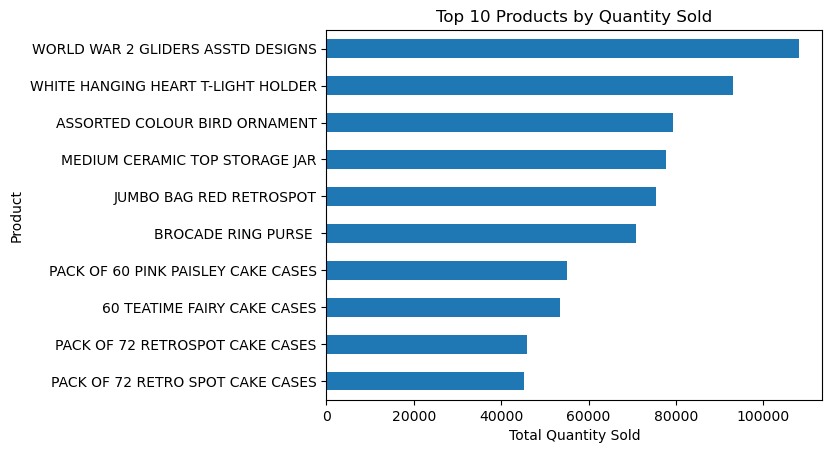

In [19]:
top_products.sort_values().plot(
    kind='barh'
)
plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')
plt.show()

Which products generate the most revenue?

In [20]:
top_products=(
    sales_df.groupby( ['StockCode', 'Description'])['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(top_products)

StockCode  Description                       
22423      REGENCY CAKESTAND 3 TIER              282511.72
85123A     WHITE HANGING HEART T-LIGHT HOLDER    250513.22
M          Manual                                151913.11
85099B     JUMBO BAG RED RETROSPOT               136139.64
84879      ASSORTED COLOUR BIRD ORNAMENT         126052.47
POST       POSTAGE                               124442.04
47566      PARTY BUNTING                         103627.78
23166      MEDIUM CERAMIC TOP STORAGE JAR         81243.22
22086      PAPER CHAIN KIT 50'S CHRISTMAS         76906.96
79321      CHILLI LIGHTS                          71631.82
Name: Revenue, dtype: float64


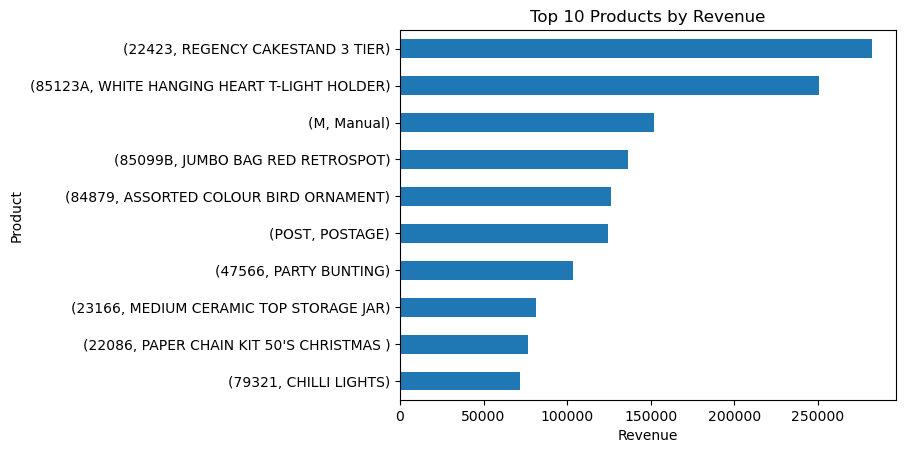

In [21]:
top_products.sort_values().plot(
    kind='barh'
)
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.show()

Which 10 customers spend the most money?

In [22]:
top_customers=(
    sales_df.groupby('Customer ID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(top_customers)

Customer ID
18102.0    597336.11
14646.0    516874.50
14156.0    313946.37
14911.0    289670.66
17450.0    246973.09
13694.0    193351.65
17511.0    168224.23
12415.0    144458.37
16684.0    141740.79
15061.0    133922.66
Name: Revenue, dtype: float64


What is the average value of a customer order?

In [23]:
order_value=sales_df.groupby('Invoice')['Revenue'].sum()

In [24]:
average_order_value=order_value.mean()
print(f"Average Order Value: {average_order_value:.2f}")

Average Order Value: 475.22


How do sales change from year to year and month to month?

In [25]:
yearly_revenue=(
    sales_df.groupby(sales_df['InvoiceDate'].dt.year)['Revenue']
    .sum()
)
print(yearly_revenue)

InvoiceDate
2009     686654.160
2010    8718063.004
2011    7920214.924
Name: Revenue, dtype: float64


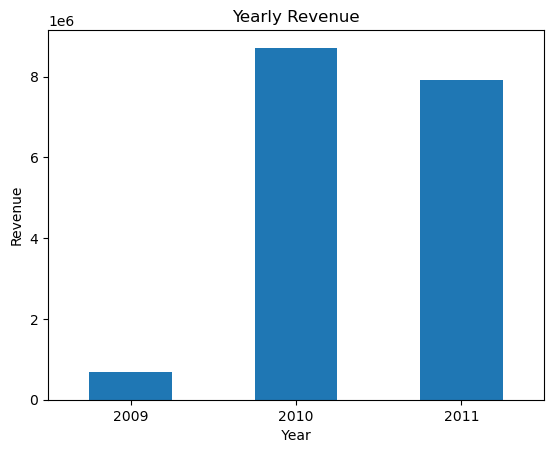

In [26]:
yearly_revenue.plot(
    kind='bar'
)
plt.title('Yearly Revenue')
plt.xlabel(' Year ')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

In [27]:
monthly_revenue=(
    sales_df.groupby([
        sales_df['InvoiceDate'].dt.year,
        sales_df['InvoiceDate'].dt.month
    ])['Revenue']
    .sum()
    
)
print(monthly_revenue.round(2))

InvoiceDate  InvoiceDate
2009         12              686654.16
2010         1               557319.06
             2               506371.07
             3               699608.99
             4               594609.19
             5               599985.79
             6               639066.58
             7               591636.74
             8               604242.65
             9               831615.00
             10             1036680.00
             11             1172336.04
             12              884591.89
2011         1               569445.04
             2               447137.35
             3               595500.76
             4               469200.36
             5               678594.56
             6               661213.69
             7               600091.01
             8               645343.90
             9               952838.38
             10             1039318.79
             11             1161817.38
             12               99713.70


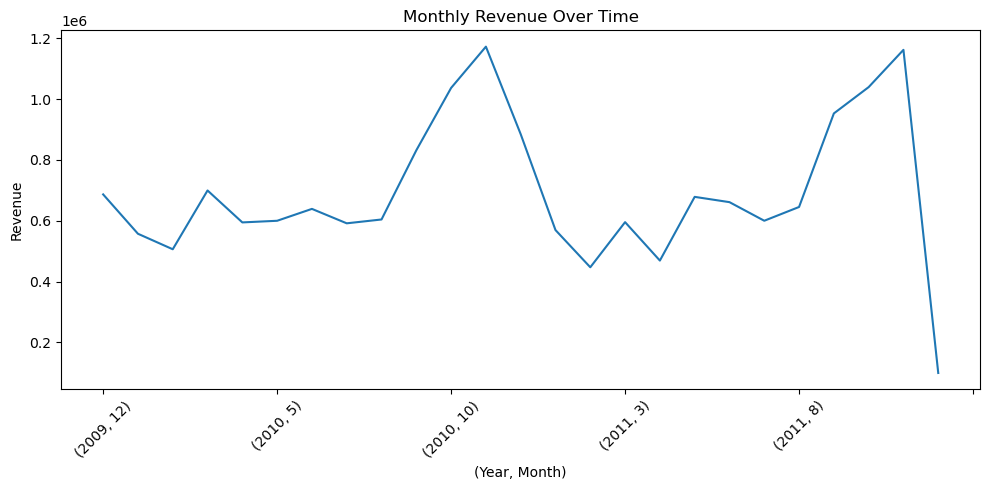

In [28]:
monthly_revenue.plot(
    kind='line',figsize=(10,5)
)
plt.title('Monthly Revenue Over Time')
plt.xlabel('(Year, Month)')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
#plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
yearly_growth = yearly_revenue.pct_change() * 100

print(yearly_growth.round(2))

InvoiceDate
2009        NaN
2010    1169.64
2011      -9.15
Name: Revenue, dtype: float64


Which countries have the highest number of unique customers?

In [30]:
customers_by_country=(
    df.groupby('Country')['Customer ID']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)
print(customers_by_country)

Country
United Kingdom    5397
Germany            106
France              94
Spain               40
Belgium             29
Portugal            24
Netherlands         23
Switzerland         22
Sweden              19
Italy               17
Name: Customer ID, dtype: int64


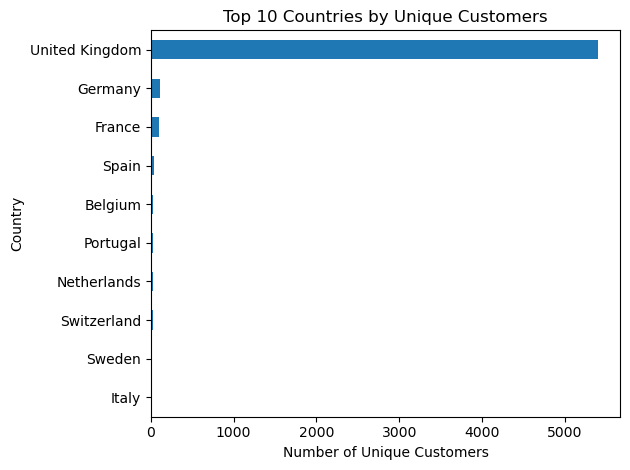

In [31]:

top_countries = customers_by_country.head(10).sort_values().plot(
    kind='barh'
)
plt.title('Top 10 Countries by Unique Customers')
plt.xlabel('Number of Unique Customers')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

How many transactions involve returns or cancellations, and what proportion of invoices do they represent?

In [32]:
cancelled=df[
       df['Invoice'].astype(str).str.startswith('C')
]
print("Cancelled rows:",len(cancelled))
print("Cancelled invoices:", cancelled['Invoice'].nunique())

Cancelled rows: 18513
Cancelled invoices: 7815


In [33]:
returns=df[df['Quantity'] < 0]
print("Rows with negative quantity:",len(returns))
print("Invoices with negative quantity:",returns['Quantity'].nunique())

Rows with negative quantity: 18513
Invoices with negative quantity: 204


In [34]:
total_invoices = df['Invoice'].nunique()

cancelled_invoice_ids = set(cancelled['Invoice'].unique())
return_invoice_ids = set(returns['Invoice'].unique())

affected_invoices = cancelled_invoice_ids | return_invoice_ids

percentage = len(affected_invoices) / total_invoices * 100

print("Total unique invoices:", total_invoices)
print("Invoices involving cancellations or negative quantities:",
      len(affected_invoices))
print("Percentage of invoices affected:", round(percentage, 2), "%")

Total unique invoices: 44278
Invoices involving cancellations or negative quantities: 7815
Percentage of invoices affected: 17.65 %


Which countries contribute the most to total revenue?

In [35]:
revenue_by_country=(
    sales_df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(revenue_by_country.round(2))

Country
United Kingdom    14343276.62
EIRE                615329.14
Netherlands         542504.32
Germany             424041.16
France              350473.19
Australia           169968.11
Spain               108862.32
Switzerland         100365.34
Sweden               91311.72
Denmark              69693.29
Name: Revenue, dtype: float64


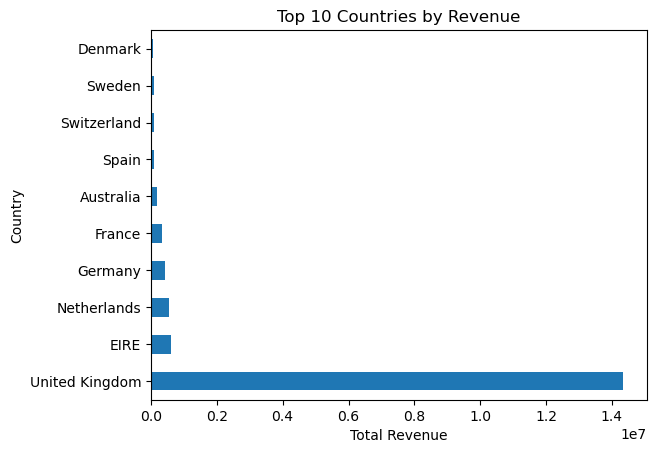

In [36]:
revenue_by_country.plot(
    kind='barh'
)
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.show()

How often do customers return to make another purchase?

In [37]:
customer_purchases=(
    df.groupby('Customer ID')['Invoice']
    .nunique()
    .head(10)
)

In [38]:
average_purchases = customer_purchases.mean()

print("Average purchases per customer:", round(average_purchases, 2))

Average purchases per customer: 5.4


In [39]:
repeat_customers = customer_purchases[customer_purchases > 1]

print("Repeat customers:", len(repeat_customers))
print("Percentage of repeat customers:",
      round(len(repeat_customers) / len(customer_purchases) * 100, 2), "%")

Repeat customers: 7
Percentage of repeat customers: 70.0 %


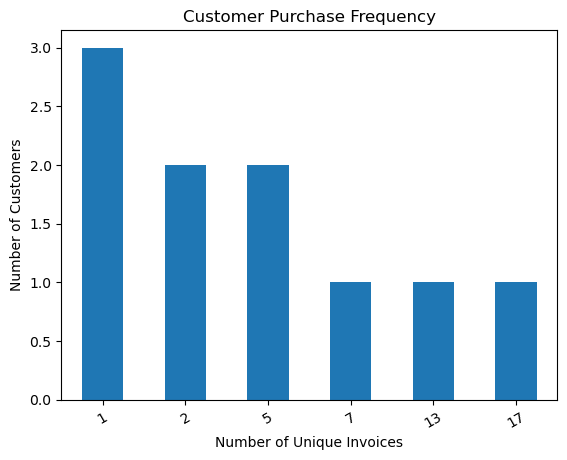

In [40]:
customer_purchases.value_counts().sort_index().plot(
    kind='bar'
)

plt.title('Customer Purchase Frequency')
plt.xlabel('Number of Unique Invoices')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.show()

Which products sell in high quantities but generate relatively little revenue?

In [41]:
product_analysis = sales_df.groupby('Description').agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('Revenue', 'sum')
)

In [42]:
product_analysis = product_analysis.sort_values(
    by='Total_Quantity',
    ascending=False
)

print(product_analysis.head(10))

                                    Total_Quantity  Total_Revenue
Description                                                      
WORLD WAR 2 GLIDERS ASSTD DESIGNS           108100       24614.48
WHITE HANGING HEART T-LIGHT HOLDER           93056      250513.22
ASSORTED COLOUR BIRD ORNAMENT                79263      126052.47
MEDIUM CERAMIC TOP STORAGE JAR               77753       81243.22
JUMBO BAG RED RETROSPOT                      75341      136139.64
BROCADE RING PURSE                           70856       14721.00
PACK OF 60 PINK PAISLEY CAKE CASES           55074       26624.25
60 TEATIME FAIRY CAKE CASES                  53411       26073.27
PACK OF 72 RETROSPOT CAKE CASES              45921       22107.06
PACK OF 72 RETRO SPOT CAKE CASES             45156       21853.08


In [43]:
high_quantity=product_analysis['Total_Quantity'].median()
low_revenue=product_analysis['Total_Revenue'].median()

low_revenue_products = product_analysis[
    (product_analysis['Total_Quantity']>high_quantity)&
    (product_analysis['Total_Revenue']<low_revenue)
].sort_values(by='Total_Quantity',ascending=False)

print(low_revenue_products.head(10))

                               Total_Quantity  Total_Revenue
Description                                                 
POPART WOODEN PENCILS ASST               9100         420.00
THE KING GIFT BAG                        8083         553.79
JAZZ HEARTS MAGNETIC MEMO PAD            7058         850.90
POP-ART FLUORESCENT PENS                 6192         388.80
WHITE WITH BLACK CATS PLATE              6091         716.23
GREEN FERN POCKET BOOK                   5685         821.85
PIECE OF CAMO STATIONERY SET             5473         766.09
ORANGE FLOWER MUG                        5395         571.71
BIRD IN TREE MUG                         4643         504.55
CARTOON  PENCIL SHARPENERS               4435         370.20


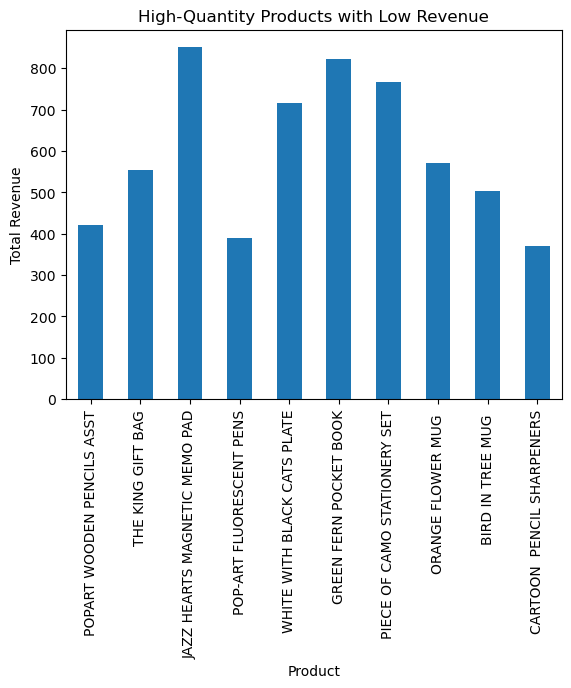

In [44]:
low_revenue_products.head(10).plot(
    kind='bar',
    y='Total_Revenue',
    legend=False
    
    
)

plt.title('High-Quantity Products with Low Revenue')
plt.xlabel('Product')
plt.ylabel('Total Revenue')
plt.show()

During which  seasons does the retailer experience its highest sales?

In [45]:
season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}

sales_df['Season'] = sales_df['InvoiceDate'].dt.month.map(season_map)

In [46]:
seasonal_sales = (
    sales_df.groupby('Season')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print(seasonal_sales)

Season
Autumn    6194605.595
Winter    3751232.268
Summer    3741594.571
Spring    3637499.654
Name: Revenue, dtype: float64


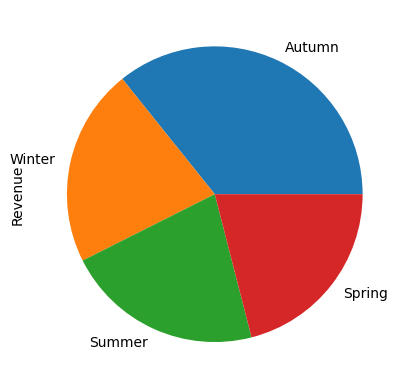

In [47]:
seasonal_sales.plot(
    kind='pie'
)

plt.show()

Is the retailer's revenue growing or declining over the available years?

In [48]:
df['Year'] = df['InvoiceDate'].dt.year

In [49]:
yearly_revenue = df.groupby('Year')['Revenue'].sum()

print(yearly_revenue)

Year
2009     663272.050
2010    8239540.544
2011    7501284.704
Name: Revenue, dtype: float64


In [50]:
yearly_growth = yearly_revenue.pct_change() * 100

print(yearly_growth.round(2))

Year
2009        NaN
2010    1142.26
2011      -8.96
Name: Revenue, dtype: float64


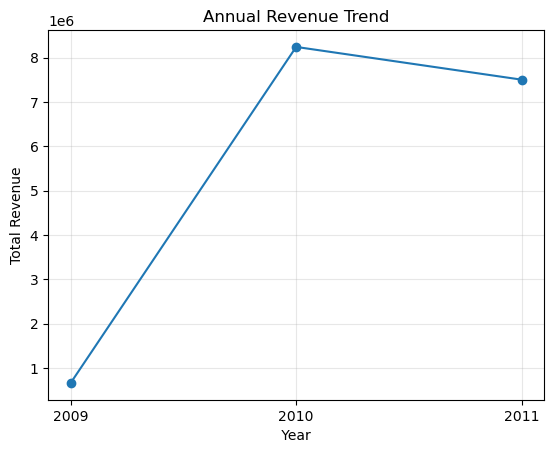

In [51]:
yearly_revenue.plot(
    kind='line',
     marker='o'
)
plt.title('Annual Revenue Trend')
plt.xlabel(' Year ')
plt.ylabel('Total Revenue')
plt.xticks(yearly_revenue.index)
plt.grid(True, alpha=0.3)
plt.show()

Compare in every years how many invoices are cancelled?

In [52]:

cancelled['Year'] = cancelled['InvoiceDate'].dt.year

cancelled_by_year = cancelled.groupby('Year')['Invoice'].nunique()

print(cancelled_by_year)

Year
2009     388
2010    4167
2011    3260
Name: Invoice, dtype: int64


C:\Users\medisa\AppData\Local\Temp\ipykernel_12880\328655623.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cancelled['Year'] = cancelled['InvoiceDate'].dt.year


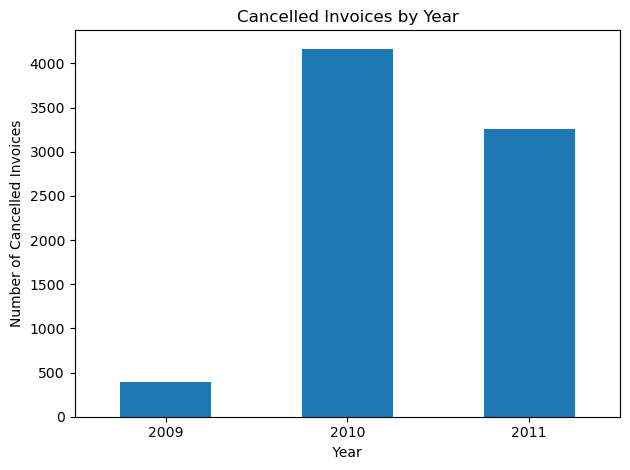

In [53]:
cancelled_by_year.plot(
    kind='bar'
)

plt.title('Cancelled Invoices by Year')
plt.xlabel(' Year ')
plt.ylabel('Number of Cancelled Invoices')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [54]:
sales_df.to_csv("online_retail_clean.csv", index=False)

In [56]:
sales_df.to_csv(
    r"C:\Users\medisa\Documents\online_retail_clean.csv",
    index=False
)

In [57]:
import os
print(os.getcwd())

C:\Users\medisa\python learning
